# CSE 258 Assignment 2: predicting play on Steam

Using the Steam v1 dataset (88,310 Australian users' libraries with playtime; 70,912
with at least one game), we study two questions about the games people own:

- **Task A (ranking):** which game will a user go on to play for at least 2 hours? We
  rank 100 candidates (the game they played + 99 games they don't own) per user.
- **Task B (engagement):** given that a user owns a game, how long do they play it?
  We predict log(1 + minutes).

**Headline results (full data, test split, 95% intervals):**
- Task A: BPR matrix factorization puts the played game in the top 10 for **65.8%** of
  users, vs 49.8% for item kNN (**+0.160 Hit@10** [+0.155, +0.165]).
- Task B: a latent factor model reduces squared error on log playtime by **7.5%** over
  a bias model (MSE 4.680 vs 5.062) and orders each user's games better (within-user
  Spearman 0.557 vs 0.525, **+0.032** [+0.029, +0.034]).

Sections follow the rubric: predictive task, exploratory analysis, modeling, evaluation,
related work. The implementation is in `src/`; this notebook reads only the committed
results of the full-data run (`results/`), so it runs anywhere without the data:

```
make results   # prep, train, validation eval -> results/
make final     # test eval, once
```

In [1]:
import inspect
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from assignment_2.modules.config.paths import REPO_ROOT
from assignment_2.modules.core.plots import use_style

RESULTS = REPO_ROOT / "results"
SUMMARIES = RESULTS / "summaries"
FIGURES = RESULTS / "figures"
use_style()

METRICS = json.loads((RESULTS / "metrics.json").read_text())
COMPARISONS = pd.read_csv(RESULTS / "comparisons.csv")
assert METRICS["sample"] == "full", "results/ should hold the full-data run"


def summary(name: str) -> pd.DataFrame:
    """A CSV from results/summaries/ (written by the full-data run)."""
    return pd.read_csv(SUMMARIES / f"{name}.csv")


def show(obj) -> None:
    """Print the source of a function or class from src/."""
    display(Markdown(f"```python\n{inspect.getsource(obj)}```"))


def metrics_table(task: str) -> pd.DataFrame:
    """Every model's metrics on validation and test: value [95% bootstrap interval]."""
    rows = {}
    for split, models in METRICS[task].items():
        for model, ms in models.items():
            rows[(model, split)] = {
                m: f"{v['value']:.3f} [{v['ci_low']:.3f}, {v['ci_high']:.3f}]"
                for m, v in ms.items()
            }
    return pd.DataFrame(rows).T.rename_axis(["model", "split"])


def comparison_table(task: str) -> pd.DataFrame:
    """Final model − baseline, paired bootstrap over users."""
    c = COMPARISONS[COMPARISONS.task == task].copy()
    c["difference [95% CI]"] = c.apply(
        lambda r: f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", axis=1
    )
    return c.pivot(index=["comparison", "split"], columns="metric", values="difference [95% CI]")

## 1. Predictive task

*Owner: @hetasj Sources: `docs/plan.md` §1–2, `docs/formulas.md`.*

TODO:
- What are we predicting, and for whom? (Tasks A and B above; why "play ≥ 2 hours" and
  not "own": plan §1.)
- How will we evaluate it? (Task A: leave-one-out, 1 + 99 popularity-weighted candidates,
  Hit@10 / NDCG@10 / MRR. Task B: 3 held-out owned games per user, MSE / MAE / within-user
  Spearman. Details in §4.1.)
- Which baselines do we compare against? (§4.2.)
- How do we assess whether the predictions are valid? (Validation for every choice, test
  scored once; paired bootstrap intervals; leak guards: §4.5.)

## 2. Exploratory analysis, data collection, and pre-processing

*Owner: @hetasj. Sources: `notebooks/eda.ipynb`, `explore_play`, `explore_engagement`.
The tables and plots below are from the full data (`results/summaries/`).*

TODO:
- **Context:** where the dataset comes from (Kang & McAuley 2018; Steam profiles of
  Australian users), what it contains (libraries with lifetime playtime, reviews, game
  metadata, bundles), and how it was collected.
- **Pre-processing:** users with empty libraries dropped; per-task splits; cold games
  dropped from held-out rows; reviews of held-out pairs removed before training (leaks).
- **Discussion:** what each plot implies for modeling (e.g. a third of owned games are
  never played → "own" is a weak preference signal, task B's target has a spike at 0;
  the item matters far more than the user for playtime).

In [2]:
stats = summary("dataset_stats").set_index("stat")["value"]
pd.DataFrame(
    {
        "users": [stats["own.all.users"], stats["play.train.users"], stats["own.train.users"]],
        "games": [stats["own.all.items"], stats["play.train.items"], stats["own.train.items"]],
        "rows": [stats["own.all.rows"], stats["play.train.rows"], stats["own.train.rows"]],
    },
    index=["all owned (user, game) pairs", "task A train", "task B train"],
).astype(int)

,users,games,rows
"all owned (user, game) pairs",70912,10978,5094082
task A train,66796,10973,4962988
task B train,70912,10966,4730596


median library: 40 games; never played: 28% of a user's library (median)


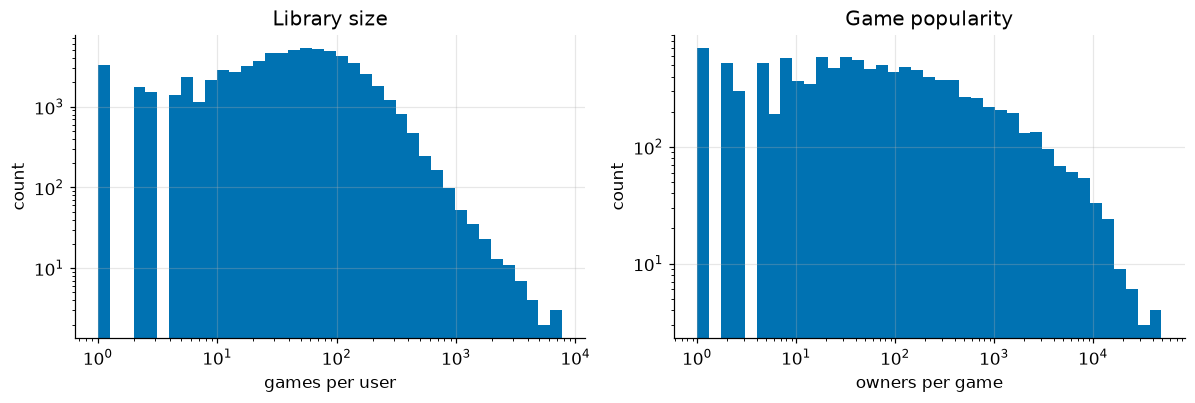

In [3]:
per_user = summary("per_user")
per_game = summary("per_game")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, values, label, title in [
    (axes[0], per_user.games, "games per user", "Library size"),
    (axes[1], per_game.owners, "owners per game", "Game popularity"),
]:
    ax.hist(values, bins=np.geomspace(1, values.max(), 40))
    ax.set(xscale="log", yscale="log", xlabel=label, ylabel="count", title=title)
plt.tight_layout()
print(f"median library: {per_user.games.median():.0f} games; "
      f"never played: {per_user.share_never_played.median():.0%} of a user's library (median)")

36.3% of owned (user, game) pairs were never played


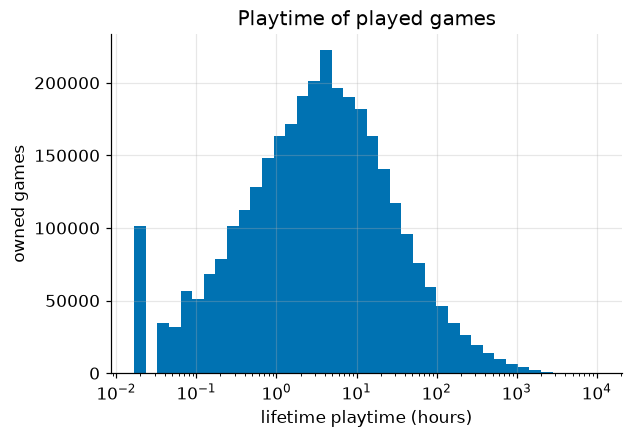

In [4]:
hist = summary("playtime_played_hist")
fig, ax = plt.subplots()
ax.bar(hist.hours_lo, hist.games, width=hist.hours_hi - hist.hours_lo, align="edge")
ax.set(xscale="log", xlabel="lifetime playtime (hours)", ylabel="owned games",
       title="Playtime of played games")
never = 1 - (per_game.players.sum() / per_game.owners.sum())
print(f"{never:.1%} of owned (user, game) pairs were never played")

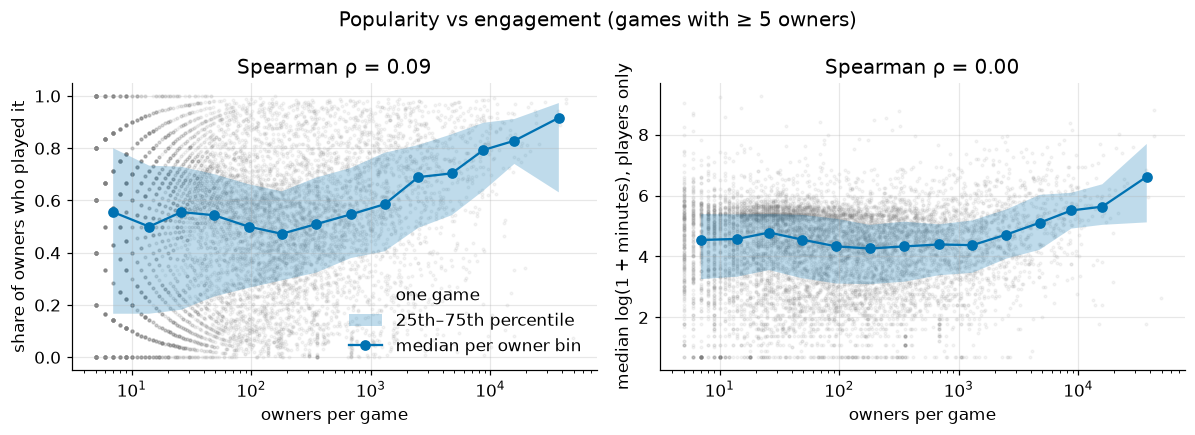

In [16]:
g = per_game[per_game.owners >= 5]
edges = np.geomspace(5, g.owners.max(), 15)
bins = pd.cut(g.owners, edges, include_lowest=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, label in [
    (axes[0], "play_rate", "share of owners who played it"),
    (axes[1], "played_median_log_minutes", "median log(1 + minutes), players only"),
]:
    b = g.groupby(bins, observed=True).agg(
        owners=("owners", "median"),
        mid=(col, "median"),
        lo=(col, lambda s: s.quantile(0.25)),
        hi=(col, lambda s: s.quantile(0.75)),
    )
    ax.scatter(g.owners, g[col], s=3, alpha=0.08, color="gray", label="one game")
    ax.fill_between(b.owners, b.lo, b.hi, alpha=0.25, label="25th–75th percentile")
    ax.plot(b.owners, b.mid, marker="o", label="median per owner bin")
    rho = g.owners.corr(g[col], method="spearman")
    ax.set(xscale="log", xlabel="owners per game", ylabel=label, title=f"Spearman ρ = {rho:.2f}")
axes[0].legend()
fig.suptitle("Popularity vs engagement (games with ≥ 5 owners)")
plt.tight_layout()

metadata for 84% of owned games; 13% appear in a bundle


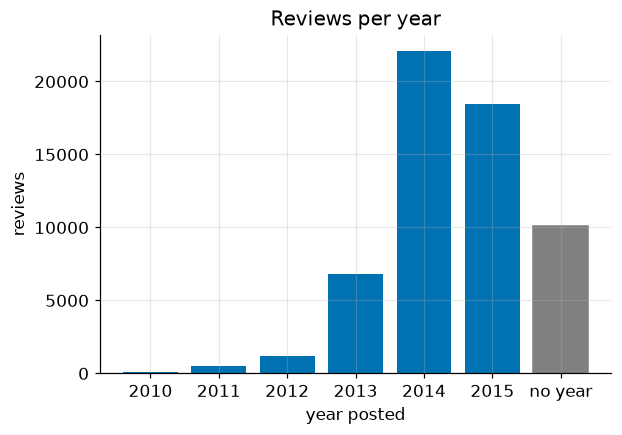

In [6]:
years = summary("reviews_per_year")
fig, ax = plt.subplots()
bars = ax.bar(years.year.astype(str), years.reviews)
bars[-1].set_color("gray")
ax.set(xlabel="year posted", ylabel="reviews", title="Reviews per year")
print(f"metadata for {per_game.has_metadata.mean():.0%} of owned games; "
      f"{per_game.in_bundle.mean():.0%} appear in a bundle")

## 3. Modeling

### 3.1 Context

**Inputs:** each user's library: which games they own and each game's lifetime playtime
(`playtime_forever`, minutes). No timestamps, ratings or prices are used; reviews are kept
out of the models (a review of a held-out game would reveal the answer).

**Outputs and objectives:**

| | Task A (play) | Task B (engagement) |
|---|---|---|
| Output | a score per (user, candidate game); higher = more likely to be played ≥ 2 h | predicted log(1 + minutes) for an owned game |
| Trained on | owned games (positives) vs sampled non-owned games | owned games only, with their playtime |
| Optimized | pairwise ranking: score(owned) > score(not owned) (BPR) | squared error on log(1 + minutes) |

Both final models are latent factor models of the same form,
score(u, i) = μ + b_u + b_i + γ_u · γ_i (BPR keeps only an item bias). What differs is the
training objective, and what each assumes about games a user doesn't own: **"not owned"
is not "disliked"** (it may be unknown, unaffordable, or exactly what they'd love). BPR
only assumes a non-owned game ranks below an owned one; the task B model never sees
non-owned games at all.

Hyperparameters were tuned on the 10% user sample's validation split (staged grids, 3
seeds per setting; `notebooks/task_a_play`, `task_b_engagement`) and applied unchanged to
the full data.

### 3.2 Task A: item kNN and BPR

**Item kNN (baseline):** a candidate's score is its highest Jaccard similarity (by
co-ownership) to any game the user has played. Simple, fast and strong: it beats every
popularity score. **BPR-MF** (Rendle et al. 2009, via `implicit`) learns γ_u, γ_i, b_i so
that games a user owns outrank games they don't, sampled per step.

Key choices (10% sample, NDCG@10, mean of 3 seeds):

| Choice | Finding |
|---|---|
| Regularization | dominates: 0.001 and 0.1 both ~0.27; 0.01–0.02 ~0.35–0.36 |
| Iterations | "played" positives peak at 100 and overfit beyond; "owned" positives are flat 100–300 |
| Factors | 64 beats 32 (+0.009); 64 = 128 = 256 → 64 |
| **Positives** | **"owned" beats "played"** (+0.031 Hit@10 [+0.018, +0.043]): with "played" positives, owned-but-unplayed games can be sampled as negatives, teaching that games like ones you own are bad; the protocol also partly rewards predicting ownership (§4.5) |

**Final BPR:** owned games as positives, 64 factors, regularization 0.01, learning rate
0.01, 100 iterations, one thread (fits repeat exactly; the GPU is used for the full run).

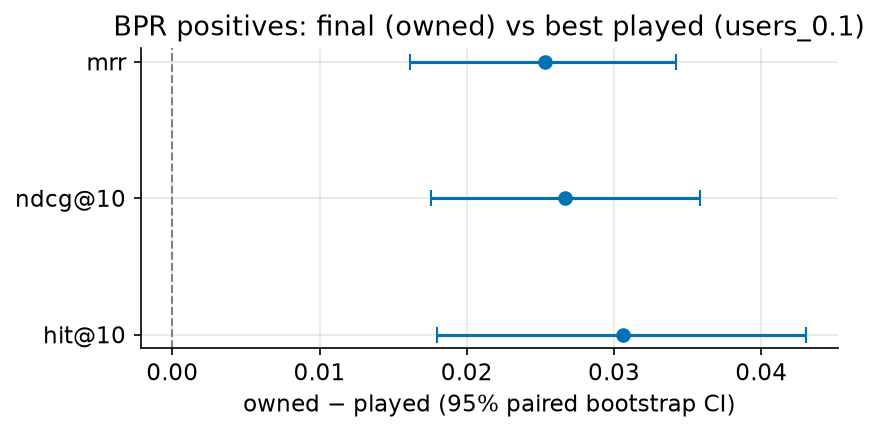

In [7]:
display(Image(FIGURES / "bpr_positives_ablation.users_0.1.png", width=650))

In [8]:
from assignment_2.modules.models.ranking.bpr import BPRModel  # noqa: E402

show(BPRModel)

```python
class BPRModel(ScoringModel):
    """BPR-MF: score(u, i) = γ_u · γ_i + b_i; positives (owned or played) outrank sampled games."""

    def __init__(
        self,
        factors: int = 64,
        learning_rate: float = 0.01,
        regularization: float = 0.01,
        iterations: int = 100,
        positives: Literal["played", "owned"] = "played",
        min_minutes: int = 120,
        use_gpu: bool = False,
        seed: int = 0,
    ) -> None:
        if use_gpu and not implicit.gpu.HAS_CUDA:
            raise RuntimeError("use_gpu=True, but this implicit build has no CUDA support")
        self.factors = factors
        self.learning_rate = learning_rate
        self.regularization = regularization
        self.iterations = iterations
        self.positives = positives
        self.min_minutes = min_minutes
        self.seed = seed
        self.use_gpu = use_gpu

        # set by fit()
        self.model = None
        self.users: pd.Index | None = None  # user_id -> row of user_factors
        self.items: pd.Index | None = None  # item_id -> row of item_factors

    def fit(self, data: TrainData) -> Self:
        rows = data.interactions
        if self.positives == "played":
            rows = rows[rows.playtime_forever >= self.min_minutes]  # games played ≥ 2 h
        # "owned": every row in play_train, including games under min_minutes
        X, self.users, self.items = interaction_matrix(rows)

        self.model = BayesianPersonalizedRanking(
            factors=self.factors,
            learning_rate=self.learning_rate,
            regularization=self.regularization,
            random_state=self.seed,
            iterations=self.iterations,
            use_gpu=self.use_gpu,
            num_threads=1,  # CPU: one thread so runs repeat exactly (ignored on GPU)
        )

        self.model.fit(X.astype(np.float32), show_progress=False)
        if self.use_gpu:
            self.model = self.model.to_cpu()  # factors back to NumPy for predict()

        return self

    def predict(self, rows: pd.DataFrame) -> NDArray[np.float64]:
        if self.model is None:
            raise RuntimeError("BPRModel.predict called before fit")
        u = self.users.get_indexer(rows.user_id)  # -1 = no positives in training
        i = self.items.get_indexer(rows.item_id)  # -1 = nobody's positive in training
        ok = (u >= 0) & (i >= 0)

        scores = np.zeros(len(rows))
        # item_factors has one extra column (the item bias), so this includes b_i
        scores[ok] = np.einsum(
            "nk,nk->n", self.model.user_factors[u[ok]], self.model.item_factors[i[ok]]
        )
        return scores
```

### 3.3 Task B: bias model and latent factor model

**Bias model (baseline):** μ + b_u + b_i, fit by alternating least squares with
shrinkage λ = 5. Within one user, μ + b_u is constant, so it orders every user's games
the same way (by b_i). **LFM** (Koren et al. 2009, Surprise `SVD`) adds γ_u · γ_i, fit by
SGD; it is the only term that can reorder a user's games.

Key choices: train on owned games only with target log(1 + minutes) and **no sampled
negatives** (task B only scores owned games, so a non-owned game at 0 would teach "not
owned = never played"); predictions are floored at 0, since log(1 + minutes) can't be
negative.

| Stage (10% sample) | Finding (MSE / Spearman) |
|---|---|
| Surprise defaults | worse than the bias model (5.30 / 0.516): `reg_all = 0.02` is far too weak for log-minutes |
| One regularization for everything | best MSE at 0.1, best Spearman at 0.2: biases and factors want different amounts |
| **Separate bias / factor regularization** | bias reg doesn't matter (0.02); factor reg 0.15 is best on both metrics |
| Factors | 100 = 200 = 400 → 100 |
| Epochs × learning rate | roughly their product matters; Surprise's defaults (20 × 0.005) tie the best MSE and win on Spearman |

**Final LFM:** 100 factors, bias regularization 0.02, factor regularization 0.15, 20
epochs, learning rate 0.005.

In [9]:
from assignment_2.modules.models.surprise import SurpriseModel  # noqa: E402

show(SurpriseModel._training_rows)
show(SurpriseModel.predict)

```python
    def _training_rows(self, data: TrainData) -> pd.DataFrame:
        pos = data.interactions
        rows = pos[["user_id", "item_id"]].assign(target=self._target(pos))
        if self.neg_ratio == 0:
            return rows.reset_index(drop=True)
        neg = sample_negatives(pos, data.exclude, self.neg_ratio, self.seed)
        return pd.concat([rows, neg.assign(target=0.0)], ignore_index=True)
```

```python
    def predict(self, rows: pd.DataFrame) -> NDArray[np.float64]:
        if self.algo is None or self.trainset is None:
            raise RuntimeError(f"{type(self).__name__}.predict called before fit")
        u = rows["user_id"].map(self.trainset._raw2inner_id_users)
        i = rows["item_id"].map(self.trainset._raw2inner_id_items)
        # Candidates only contain train users and items, so a miss is a pipeline bug.
        missing = u.isna() | i.isna()
        if missing.any():
            raise ValueError(
                f"{int(missing.sum()):,} rows have users/items not seen in training, "
                f"e.g. {rows.loc[missing, ['user_id', 'item_id']].iloc[0].tolist()}"
            )
        pred = self._score(u.to_numpy(np.int64), i.to_numpy(np.int64))
        # log1p(minutes) can't be negative; clipping only removes impossible predictions
        return np.maximum(pred, 0.0) if self.target == "minutes" else pred
```

### 3.4 Trade-offs

| Model | Complexity | Fit time, full data | Strengths | Weaknesses |
|---|---|---|---|---|
| item kNN | none to tune | 2 s | transparent; captures bundle and franchise structure | can't generalize beyond co-ownership; ignores how much games are played |
| user kNN | none to tune | infeasible | captures taste neighborhoods | user × user similarity doesn't fit in memory at 70k users (evaluated on the 10% sample only) |
| BPR | 4 hyperparameters, sensitive to regularization | 4 s (GPU; ~2 min CPU) | optimizes ranking directly; learns from all owned games | sampled negatives; GPU build pins `rmm` versions (`implicit` 0.7.3) |
| bias model | λ only | 20 s | strong, stable baseline | no personalization within a user |
| LFM | 5+ hyperparameters; defaults fail badly | 34 s (single-threaded) | personalizes order within a user; best on every metric | needs careful regularization; one peak where the truth has two (§4.4) |

**Tried and set aside:** treating non-owned games as confident zeros (pointwise SVD with
sampled negatives: trains the model to dislike the games it should recommend); a hurdle
model for never-played games and kNN regressors for task B (neither beats the LFM; §4.4).

## 4. Evaluation

### 4.1 Protocol and metrics

**Task A.** Per user, one game played ≥ 120 minutes is held out for validation and one
for test. Each is ranked against 99 games the user doesn't own, drawn once in proportion
to popularity, so every model ranks the same 100 rows and popularity alone can't find
the answer (uniform negatives made the held-out game ~90× more popular than the
negatives; popularity-weighted, ~3×). With one relevant game per user:

- **Hit@10:** is it in the top 10? (a 10-item store page)
- **NDCG@10:** 1 / log₂(rank + 1) if in the top 10, else 0: how high on the page
- **MRR:** 1 / rank, over the whole list

These are the metrics SASRec (Kang & McAuley 2018) uses on this dataset, ranking the
held-out item against 100 sampled negatives (we use 99). Caveat: sampled-candidate metrics can rank models
differently than full-catalogue metrics (Krichene & Rendle 2020), so these are
comparisons on a fixed shared candidate table, not full-catalogue estimates.

**Task B.** Per user (≥ 7 owned games), 3 owned games held out for validation and 3 for
test, including never-played games. Target y = log(1 + minutes): playtime is extremely
heavy-tailed, and on the log scale being off by 2× costs the same at 1 hour as at 100.

- **MSE, MAE** on y: the loss the model minimizes; a log error e is a ratio exp(e)
- **Within-user Spearman** over each user's 3 games: does the model order them right?
  μ + b_u cancels within a user, so this isolates what γ_u · γ_i adds; MSE alone mostly
  rewards getting the biases right.

**Both tasks:** metrics are per user, then averaged (every user counts once). Intervals
are 95% bootstrap intervals over users (1,000 resamples); differences use a paired
bootstrap (same users for both models), so a difference is real if its interval
excludes 0. Definitions: `docs/formulas.md`.

### 4.2 Baselines

Every candidate baseline on the 10% sample's validation split (`explore_play`,
`explore_engagement`), to choose the bar each final model has to beat:

| Task A | Hit@10 | NDCG@10 | MRR |
|---|---|---|---|
| random | 0.090 | 0.041 | 0.049 |
| owner popularity | 0.357 | 0.213 | 0.190 |
| play popularity | 0.405 | 0.246 | 0.220 |
| user kNN (cosine) | 0.440 | 0.268 | 0.237 |
| **item kNN (Jaccard): the bar** | **0.497** | **0.303** | **0.264** |
| BPR (final settings) | 0.619 | 0.388 | 0.335 |

| Task B | MSE | MAE | Within-user Spearman |
|---|---|---|---|
| global mean | 9.890 | 2.784 | undefined |
| user mean | 8.902 | 2.567 | undefined |
| owner popularity | | | 0.165 |
| item mean | 5.587 | 1.871 | 0.536 |
| **bias model: the bar** | **5.007** | **1.765** | **0.542** |
| LFM (final settings) | 4.690 | 1.700 | 0.556 |

The strongest baseline of each task (item kNN; the bias model) is then retrained and
scored on the full data alongside the final model.

### 4.3 Task A results (full data)

,,hit@10,ndcg@10,mrr
model,split,,,
bpr,valid,"0.657 [0.653, 0.661]","0.413 [0.410, 0.416]","0.354 [0.351, 0.357]"
item_knn_rank,valid,"0.499 [0.495, 0.502]","0.305 [0.302, 0.308]","0.266 [0.263, 0.269]"
bpr,test,"0.658 [0.654, 0.662]","0.413 [0.411, 0.416]","0.355 [0.352, 0.358]"
item_knn_rank,test,"0.498 [0.494, 0.502]","0.304 [0.301, 0.307]","0.265 [0.263, 0.268]"


metric                                      hit@10                      mrr  \
comparison          split                                                     
bpr − item_knn_rank test   +0.160 [+0.155, +0.165]  +0.089 [+0.086, +0.092]   
                    valid  +0.158 [+0.153, +0.163]  +0.088 [+0.084, +0.091]   

metric                                     ndcg@10  
comparison          split                           
bpr − item_knn_rank test   +0.110 [+0.106, +0.113]  
                    valid  +0.108 [+0.104, +0.112]

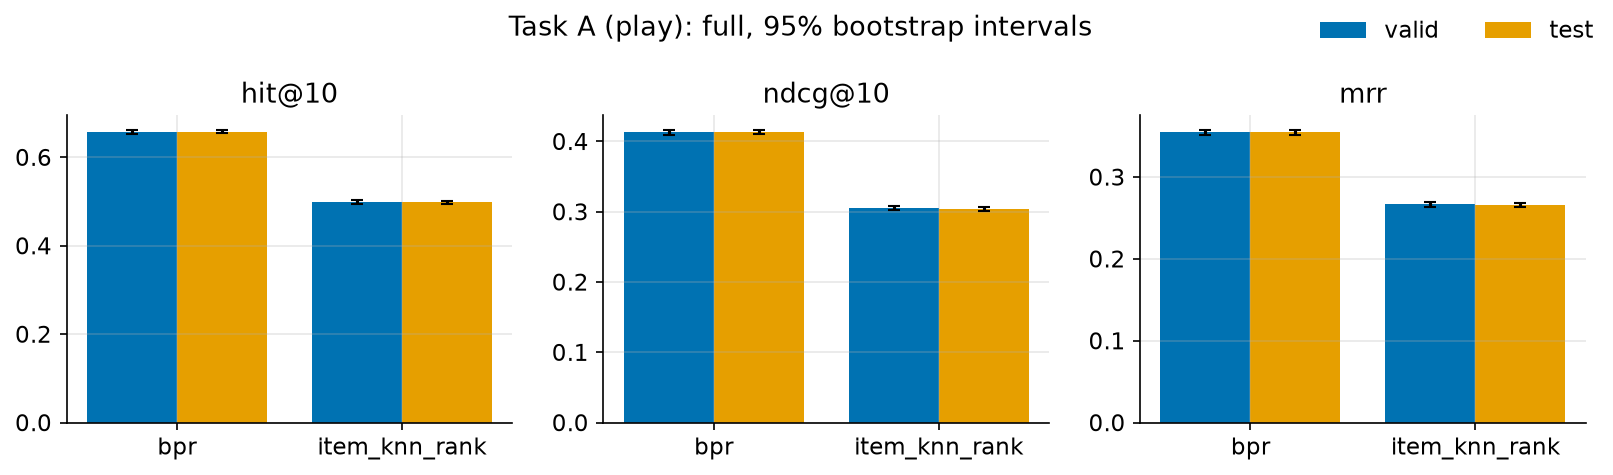

In [10]:
display(metrics_table("play"), comparison_table("play"))
display(Image(FIGURES / "play_results.png", width=850))

In [11]:
def placement(ranks: pd.DataFrame) -> pd.DataFrame:
    """Where the held-out game lands among the 100 candidates, from per-rank user counts."""
    out = {}
    for model, g in ranks.groupby("model"):
        r = np.repeat(g["rank"].to_numpy(), g["users"].to_numpy())
        out[model] = {
            "top-1 rate": (r == 1).mean(),
            "Hit@5": (r <= 5).mean(),
            "Hit@10": (r <= 10).mean(),
            "median rank": np.median(r),
            "median rank | top-10 hit": np.median(r[r <= 10]),
        }
    return pd.DataFrame(out).T.round(3)


placement(summary("play_test_ranks"))

,top-1 rate,Hit@5,Hit@10,median rank,median rank | top-10 hit
bpr,0.216,0.501,0.658,5.0,3.0
item_knn_rank,0.155,0.361,0.498,11.0,3.0


**Takeaways (test):**
- BPR puts the game the user went on to play in the top 10 for 65.8% of users (item
  kNN 49.8%; random would be 10%), and first for 21.6% (15.5%). The gain is real on every
  metric: +0.160 Hit@10 [+0.155, +0.165], +0.110 NDCG@10, +0.089 MRR.
- The median rank of the played game is 5 of 100 for BPR, 11 for item kNN.
- BPR gains from 10× the data (Hit@10 0.619 → 0.658), item kNN doesn't (0.497 → 0.498): a
  learned model benefits from more users, a similarity heuristic barely changes.

### 4.4 Task B results (full data)

,,mse,mae,spearman
model,split,,,
lfm,valid,"4.693 [4.659, 4.727]","1.694 [1.688, 1.701]","0.559 [0.555, 0.564]"
bias_eng,valid,"5.065 [5.029, 5.100]","1.771 [1.765, 1.778]","0.531 [0.526, 0.536]"
lfm,test,"4.680 [4.646, 4.715]","1.694 [1.687, 1.701]","0.557 [0.553, 0.562]"
bias_eng,test,"5.062 [5.025, 5.097]","1.772 [1.765, 1.778]","0.525 [0.521, 0.530]"


metric                                    mae                      mse  \
comparison     split                                                     
lfm − bias_eng test   -0.078 [-0.081, -0.076]  -0.382 [-0.394, -0.368]   
               valid  -0.077 [-0.079, -0.074]  -0.372 [-0.384, -0.359]   

metric                               spearman  
comparison     split                           
lfm − bias_eng test   +0.032 [+0.029, +0.034]  
               valid  +0.028 [+0.026, +0.031]

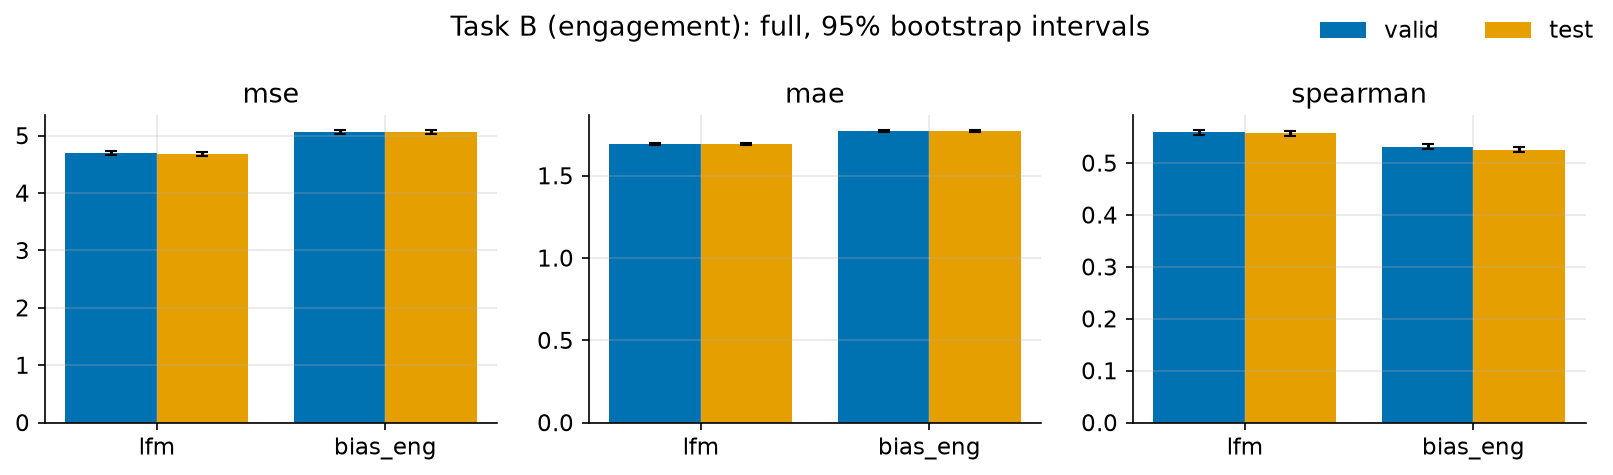

In [12]:
display(metrics_table("engagement"), comparison_table("engagement"))
display(Image(FIGURES / "engagement_results.png", width=850))

In [13]:
summary("engagement_test_headline").set_index("model").round(3)

,mse,mse_played_only,mse_if_zeros_perfect,median_ratio,within_2x,within_10x,auc_never_played,pred_std,true_std
model,,,,,,,,,
lfm,4.680,4.160,2.887,4.039,0.270,0.722,0.867,2.188,3.119
bias_eng,5.062,4.376,3.036,4.450,0.258,0.695,0.847,2.135,3.119


**Takeaways (test):**
- The LFM beats the bias model on every metric: MSE −0.382 [−0.394, −0.368] (−7.5%), MAE
  −0.078, within-user Spearman +0.032 [+0.029, +0.034]. The Spearman gain is the evidence
  that the latent factors personalize; it is real but small next to the step from owner
  popularity to the item mean (0.165 → 0.536): which game it is explains most of how
  much people play it.
- In plain terms, a prediction is typically off by a factor of 4.0 in (1 + minutes) (bias
  model 4.4); 72% are within 10×.

**Where the error comes from.** The target has two peaks: 31% of owned games were never
played, the rest form a broad hump. The model has one peak, between them:

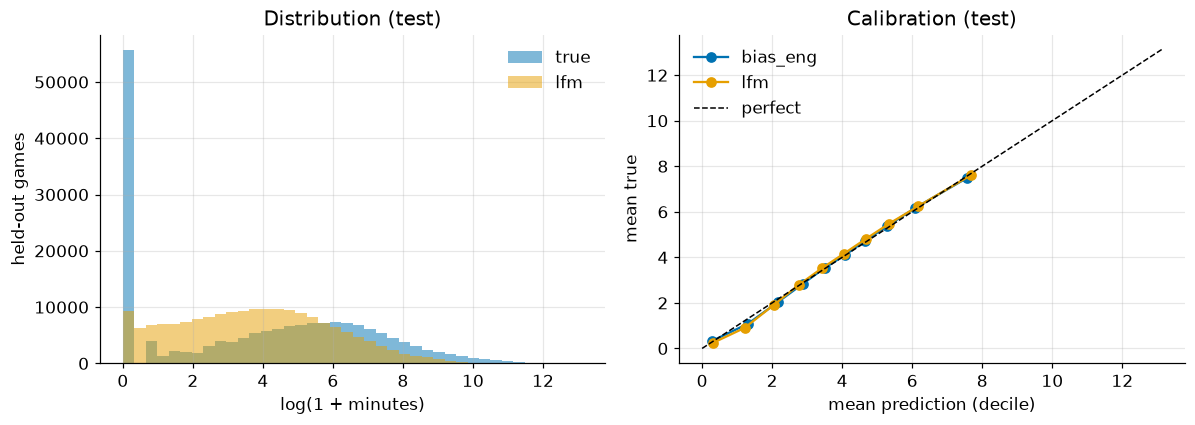

In [14]:
hist = summary("engagement_test_hist")
cal = summary("engagement_test_calibration")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
width = hist.log_minutes_hi - hist.log_minutes_lo
ax1.bar(hist.log_minutes_lo, hist["true"], width=width, align="edge", alpha=0.5, label="true")
ax1.bar(hist.log_minutes_lo, hist["lfm"], width=width, align="edge", alpha=0.5, label="lfm")
ax1.set(xlabel="log(1 + minutes)", ylabel="held-out games", title="Distribution (test)")
ax1.legend()
for model, c in cal.groupby("model"):
    ax2.plot(c.mean_pred, c.mean_true, "o-", label=model)
lim = [0, hist.log_minutes_hi.max()]
ax2.plot(lim, lim, "k--", lw=1, label="perfect")
ax2.set(xlabel="mean prediction (decile)", ylabel="mean true", title="Calibration (test)")
ax2.legend()
plt.tight_layout()

In [15]:
(summary("engagement_test_buckets").query("model == 'lfm'").set_index("bucket")
 .drop(columns="model").round(3))

,share_of_rows,median_pred_minutes,mean_error_log,mse,share_of_squared_error
bucket,,,,,
never (0),0.306,3.578,1.872,5.858,0.383
≤ 1 h,0.193,22.197,0.589,2.987,0.123
1–10 h,0.262,85.167,-0.852,3.027,0.169
10–100 h,0.190,282.618,-1.764,5.524,0.224
100 h+,0.049,1301.657,-2.634,9.602,0.100


- The LFM is well calibrated (in every prediction decile the mean truth matches the mean
  prediction) but its predictions are narrower than the truth (std 2.19 vs 3.12): when it
  can't tell whether a game was never played or played for hours, squared error makes
  hedging between the two the best answer.
- Never-played games are 38% of the squared error (31% of rows); games played 10 h+ are
  32% (24% of rows). A perfect never-played detector would cut MSE from 4.680 to 2.887,
  but nothing we tried ranks never-played games better than the LFM itself (AUC 0.867;
  item zero rate, user zero rate and item kNN signals are all lower on the 10% sample), so
  a two-stage hurdle model was not pursued.

### 4.5 Validity

- **Test matches validation** for every model (e.g. BPR Hit@10 0.657 vs 0.658; LFM MSE
  4.693 vs 4.680): no sign of overfitting to validation, which chose every setting. Test
  was scored once, after the models were frozen.
- **No leakage:** held-out pairs never appear in training, as positives or sampled
  negatives; reviews of held-out games are removed before training.
- **Limitations:** task A's held-out game is always owned and its negatives never are, so
  the protocol partly rewards predicting ownership (one reason "owned" positives help
  BPR); sampled-candidate metrics aren't full-catalogue metrics; hyperparameters were
  tuned on a 10% sample (re-tuning on the full data might find a larger BPR).

## 5. Related work

*Owner: @Amir-Mirkazemi. References: `docs/plan.md`.*

TODO:
- **This dataset:** Kang & McAuley, *Self-Attentive Sequential Recommendation* (ICDM
  2018) introduced it for next-item prediction with Hit@10 / NDCG@10 on 100 sampled
  candidates. How does our task (play ≥ 2 h, popularity-weighted negatives, no sequence)
  differ, and why aren't the numbers directly comparable?
- **Implicit feedback and ranking:** Rendle et al., *BPR* (UAI 2009); Hu, Koren &
  Volinsky, *Collaborative Filtering for Implicit Feedback Datasets* (ICDM 2008), which
  uses play-like counts as confidence.
- **Neighborhood and latent factor models:** Sarwar et al., *Item-Based Collaborative
  Filtering* (WWW 2001); Koren, Bell & Volinsky, *Matrix Factorization Techniques for
  Recommender Systems* (IEEE Computer 2009).
- **Evaluation:** Krichene & Rendle, *On Sampled Metrics for Item Recommendation* (KDD
  2020).
- How do our results match or differ from what has been reported (e.g. BPR beating item
  kNN; latent factors adding little over biases for engagement)?